# Exploración de datos para el clustering de estaciones (P3)

Reviso la duración de los viajes antes de limpiar, para ver los outliers y justificar las reglas de limpieza de `dataset_clustering.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mibici_ml.config import (
    CLUSTERING_MAX_TRIP_HOURS,
    CLUSTERING_MIN_TRIP_SECONDS,
    CLUSTERING_STATIONS_FILE,
    CLUSTERING_TRIP_FILES,
    RAW_DATA_DIR,
)
from mibici_ml.dataset_clustering import (
    convertir_tipos,
    leer_viajes,
    limpiar_estaciones,
    limpiar_viajes,
)

# Viajes sin limpiar, leídos con las mismas funciones del módulo
meses = [leer_viajes(RAW_DATA_DIR / nombre)[0] for nombre in CLUSTERING_TRIP_FILES]
viajes = convertir_tipos(pd.concat(meses, ignore_index=True))
viajes["duracion_min"] = (viajes["fin"] - viajes["inicio"]).dt.total_seconds() / 60
viajes["misma_estacion"] = viajes["origen_id"] == viajes["destino_id"]

print(f"Viajes originales: {len(viajes):,}")
viajes["duracion_min"].describe(percentiles=[0.01, 0.5, 0.99, 0.999]).round(2)

2026-10-18 19:35:46.839 | INFO     | mibici_ml.config:<module>:11 - PROJ_ROOT path is: E:\Documentos\MNA\OPSAA\TC5061-MiBici-Equipo50


Viajes originales: 4,874,666


count    4874666.00
mean          10.98
std           10.03
min            0.00
1%             0.17
50%            9.37
99%           33.40
99.9%         59.14
max         5920.05
Name: duracion_min, dtype: float64

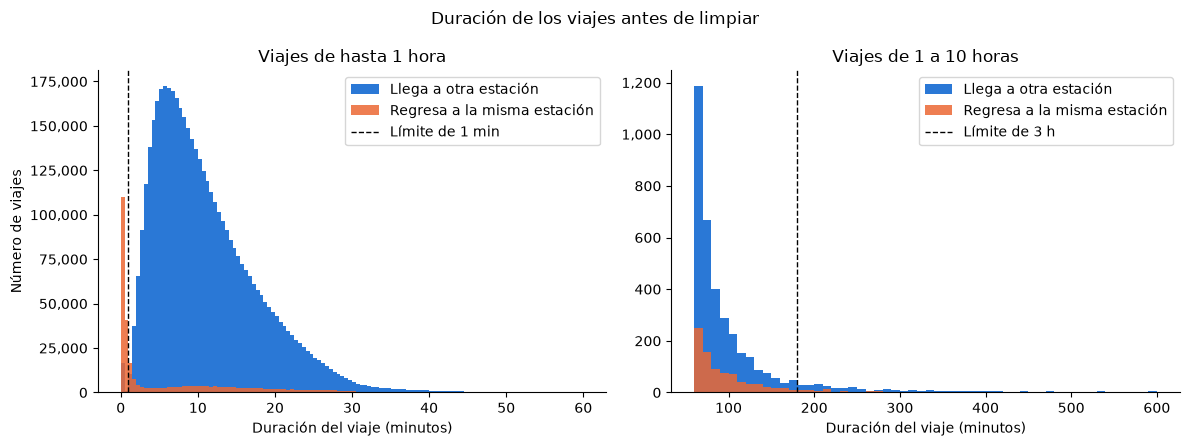

In [2]:
limite_min = CLUSTERING_MIN_TRIP_SECONDS / 60
limite_max = CLUSTERING_MAX_TRIP_HOURS * 60
otra = viajes.loc[~viajes["misma_estacion"], "duracion_min"]
misma = viajes.loc[viajes["misma_estacion"], "duracion_min"]

# Dos paneles con escala normal: en uno solo la cola de viajes largos no se alcanza a ver
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
paneles = [
    (ax1, np.arange(0, 60.5, 0.5), limite_min, "Límite de 1 min", "Viajes de hasta 1 hora"),
    (ax2, np.arange(60, 610, 10), limite_max, "Límite de 3 h", "Viajes de 1 a 10 horas"),
]
for ax, bins, limite, texto, titulo in paneles:
    ax.hist(otra, bins=bins, color="#2a78d6", label="Llega a otra estación")
    ax.hist(misma, bins=bins, color="#eb6834", alpha=0.85, label="Regresa a la misma estación")
    ax.axvline(limite, color="black", linestyle="--", linewidth=1, label=texto)
    ax.set_title(titulo)
    ax.set_xlabel("Duración del viaje (minutos)")
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()
ax1.set_ylabel("Número de viajes")
fig.suptitle("Duración de los viajes antes de limpiar")
fig.tight_layout()
plt.show()


En el panel de la izquierda, los viajes que llegan a otra estación (azul) forman una campana con el pico cerca de 6 minutos, y casi todos terminan antes de 40 minutos. Los que regresan a la misma estación (naranja) tienen un pico aparte antes de 1 minuto: son arranques falsos, cuando alguien saca la bici y la devuelve enseguida. En el panel de la derecha se ve que los viajes de más de 1 hora son pocos y que después de 3 horas casi desaparecen. Son 545 viajes, algunos de más de un día, que corresponden a bicis mal ancladas o errores de registro.


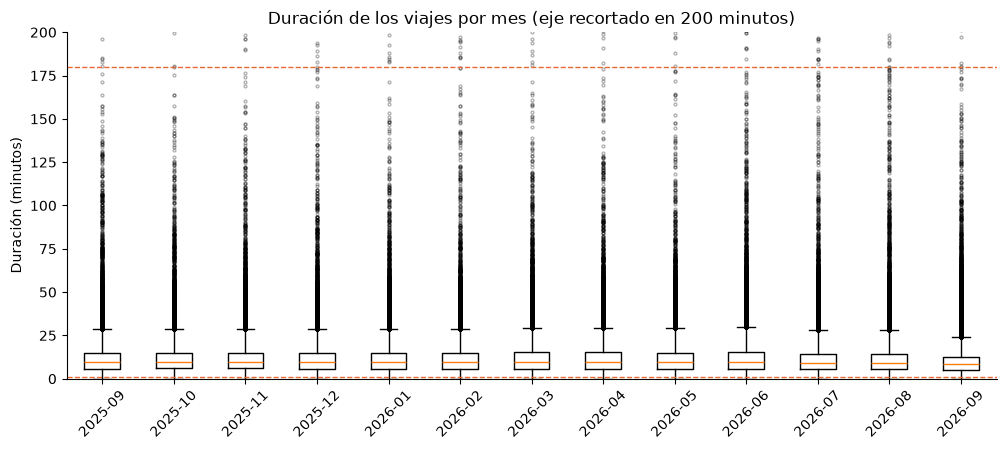

In [3]:
viajes["mes"] = viajes["inicio"].dt.strftime("%Y-%m")
grupos = [g for _, g in viajes.groupby("mes")["duracion_min"]]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.boxplot(
    grupos,
    tick_labels=sorted(viajes["mes"].unique()),
    flierprops={"markersize": 2, "alpha": 0.3},
)
for y in [limite_min, limite_max]:
    ax.axhline(y, color="#eb6834", linestyle="--", linewidth=1)
# Recorto el eje en 200 min para que se vean las cajas; arriba quedan unos cientos de viajes
ax.set_ylim(0, 200)
ax.set_ylabel("Duración (minutos)")
ax.set_title("Duración de los viajes por mes (eje recortado en 200 minutos)")
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)
plt.show()


Recorté el eje en 200 minutos para que se vean las cajas. Las líneas naranjas marcan los límites de 1 minuto y 3 horas. La duración es muy parecida en todos los meses, con una mediana de entre 8 y 10 minutos, así que no hay un mes con datos raros. Solo septiembre de 2026 tiene viajes un poco más cortos (mediana de 8.4 minutos), pero la diferencia es pequeña. Los bigotes llegan a unos 29 minutos y el boxplot marca como outliers todo lo que pasa de ahí, por la regla del IQR. No uso esa regla porque un viaje de 40 minutos o de 1 hora es un uso real de la bici. Por eso el límite de arriba es de 3 horas, que separa los viajes normales de los errores, como se ve en el panel derecho del histograma.

In [4]:
estaciones = limpiar_estaciones(RAW_DATA_DIR / CLUSTERING_STATIONS_FILE)
columnas = ["viaje_id", "inicio", "fin", "origen_id", "destino_id"]
_, resumen = limpiar_viajes(viajes[columnas], set(estaciones["estacion_id"]))

tabla = pd.Series(resumen, name="viajes").to_frame()
tabla["% del total"] = (tabla["viajes"] / resumen["registros_originales"] * 100).round(2)
tabla

,viajes,% del total
registros_originales,4874666,100.00
duplicados,758,0.02
valores_invalidos,0,0.00
fuera_de_rango,0,0.00
duracion_negativa,0,0.00
arranque_falso,150645,3.09
duracion_mayor_al_maximo,545,0.01
estacion_sin_nomenclatura,3888,0.08
registros_limpios,4718830,96.80


En total la limpieza quita el 3.2% de los viajes, y casi todo son arranques falsos (3.1%). Se conserva el 96.8% de los datos.